# 04 · Tier 3: LLM (Claude API)

**How it works.** No training at all: each comment is sent to Claude with a short instruction
("reply with one word: positive, neutral or negative") and the answer is used as the label.
*Zero-shot* = no labelled examples in the prompt. The model's general knowledge of Tagalog,
slang and sarcasm is what we are testing.

**Setup (one time)**
```bash
pip install anthropic python-dotenv
```
Create a file called `.env` in the project root (it is in `.gitignore`, never commit it):
```
ANTHROPIC_API_KEY=sk-ant-...
```

**Cost control.** Every answer is cached in `results/llm_cache.jsonl`. Re-running this notebook
reads from the cache and makes no API calls. 300 test + 30 hard comments with Claude Haiku 5.5
costs about one US cent.

The prompts are in `notebooks/src/llm.py` and documented in `prompts.md`.

In [1]:
import sys, pathlib
NB_DIR = pathlib.Path.cwd().resolve()
if NB_DIR.name != "notebooks":        # Jupyter was started in the repo root instead of notebooks/
    NB_DIR = NB_DIR / "notebooks"
ROOT = NB_DIR.parent                  # repo root (data/, results/, prompts.md ...)
sys.path.insert(0, str(NB_DIR))       # so "from src import ..." finds notebooks/src/

import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

from src import config, data, evaluate as ev
from src.profanity import mask, mask_frame     # curse words are masked in everything shown
from src.llm import ClaudeClassifier, PROMPTS, MODEL

load_dotenv(ROOT / ".env")
print("API key found:", os.getenv("ANTHROPIC_API_KEY") is not None)   # never print the key itself

train, test = data.load_split()
hard = data.load_hard_cases()

API key found: True


In [2]:
print(PROMPTS["v2_taglish"])

You classify the sentiment of YouTube comments on a FlipTop rap battle video (Team LA = Loonie & Abra vs Team SS = Shehyee & Smugglaz). Comments are in Tagalog, English or Taglish (mixed), with slang, misspellings and profanity.
Labels:
- positive: praise, hype, enjoyment, support for a battler or team, nostalgic appreciation ("classic", "solid", "lupet", "galing", "idol"). A curse word used as hype together with praise ("... ang lupet") is positive.
- negative: insults or curses aimed at battlers, fans or judges; criticism (corny, pikon, mayabang, luto/rigged, walang kwenta); mocking a battler; angry disagreement with the result; taunting the other side's fans.
- neutral: questions, dates or "who's still watching", timestamps, like-bait, quoted bars with no opinion, factual remarks, requests, laughter only, or mixed with no clear side.
With pero / kaso / but, weigh the part after it. Sarcasm counts as its real meaning.
Reply with exactly one word: positive, neutral, or negative.


In [3]:
clf = ClaudeClassifier(model=MODEL, prompt_version="v2_taglish")
for s in ["Ang galing ni Smugglaz!", "Hindi magaling si Loonie dito.", "Sobrang lupet ni Abra!",
          "Wow, ang galing mag-choke ni Shehyee. Idol talaga.", "Sino pa nanonood ngayong 2026?"]:
    print(f"{clf.classify(s)['label']:9s} <- {s}")

positive  <- Ang galing ni Smugglaz!
negative  <- Hindi magaling si Loonie dito.
positive  <- Sobrang lupet ni Abra!
neutral   <- Wow, ang galing mag-choke ni Shehyee. Idol talaga.
neutral   <- Sino pa nanonood ngayong 2026?


## 1. Score the 300 test comments + 30 hard cases

The LLM gets `text_clean` (case, emoji and punctuation kept).
**Sec / 1k** is the average API response time × 1,000 (calls made one after another).
**Cost / 1k** comes from the real token counts the API returned.

50/300 done (55 API calls so far)
100/300 done (105 API calls so far)
150/300 done (155 API calls so far)
200/300 done (205 API calls so far)
250/300 done (255 API calls so far)
300/300 done (305 API calls so far)
{'n': 300, 'avg_input_tokens': 431.29333, 'avg_output_tokens': 4.28, 'cost_per_1k_usd': 0.04527, 'sec_per_1k': 886.59667, 'unparsed': 0}
== Claude Haiku 5.5 zero-shot ==
              precision    recall  f1-score   support

    negative      0.864     0.870     0.867       131
     neutral      0.696     0.764     0.728        72
    positive      0.831     0.763     0.796        97

    accuracy                          0.810       300
   macro avg      0.797     0.799     0.797       300
weighted avg      0.813     0.810     0.811       300



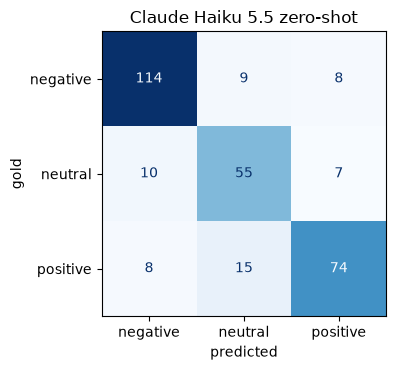

{'model': 'Claude Haiku 5.5 zero-shot',
 'tier': '3 LLM',
 'accuracy': 0.81,
 'macro_f1': 0.7970319660048301,
 'hard_acc': 0.9,
 'sec_per_1k': 886.5966666666666,
 'cost_per_1k_usd': 0.045269333333333335}

In [4]:
MODEL_NAME = "Claude Haiku 5.5 zero-shot"

pred_llm = clf.predict(list(test["text_clean"]))
hard_llm = clf.predict(list(hard["text_clean"]), verbose_every=0)
stats = clf.stats(list(test["text_clean"]))
print({k: round(v, 5) if isinstance(v, float) else v for k, v in stats.items()})

ev.report(test["label"], pred_llm, MODEL_NAME)
ev.plot_confusion(test["label"], pred_llm, MODEL_NAME)
plt.show()
ev.save_run(MODEL_NAME, "3 LLM", test, pred_llm, hard, hard_llm,
            stats["sec_per_1k"], stats["cost_per_1k_usd"])

## 2. Where the LLM disagrees with the gold label

In [5]:
pd.set_option("display.max_colwidth", 140)
err = test.assign(pred=pred_llm)
err = err[err["pred"] != err["label"]]
print(len(err), "disagreements")
mask_frame(err[["text_clean", "label", "pred"]].head(20))

57 disagreements


,text_clean,label,pred
3,24:05 check nyo ulit.. ahahaha dami ko tlaga tawa..,positive,neutral
4,C******a Na Yan .. C******a Na Yan .. C******a Na Yan ...,neutral,negative
6,2 n 1 kawawa ni abra XD,neutral,negative
21,Hala Hnd Nohhh,neutral,negative
29,more than thrice nag choke si lonie.. first time yon! lakas SS!,positive,negative
32,Payat pa ni sheyee,neutral,negative
44,sabog na sabog si smuglazz,negative,positive
49,Alams na kung bakt malakas mang distract tapos bakit ganyan sila smugg dahil pinag gaganti nila sila krazy mix kase ginawa ng team la ya...,neutral,positive
51,Thumbs up kung tingin nyo mas finals pa to - _ -,positive,neutral
52,Luto sir,positive,negative


In [6]:
mask_frame(pd.DataFrame({"text": hard["text"], "gold": hard["label"], "llm": hard_llm, "phenomenon": hard["phenomenon"]}))

,text,gold,llm,phenomenon
0,Hindi magaling si Loonie dito.,negative,negative,negation
1,Hindi naman pangit yung laban eh.,positive,positive,negation
2,Walang kwenta yung rebuttal nila.,negative,negative,negation
3,Wala akong masabi sa galing ni Smugglaz.,positive,positive,negation
4,T**g i*a ang lupet ng bara ni Abra!,positive,positive,profanity_as_praise
5,"P*******a, ang bangis talaga ng round 3!",positive,positive,profanity_as_praise
6,"G**o, pinakasolid na dos por dos 'to.",positive,positive,profanity_as_praise
7,"Wow, ang galing mag-choke ni Shehyee. Idol talaga.",negative,neutral,sarcasm
8,"Ang husay naman ng judges, 7-0 agad. Sobrang fair talaga 🙄",negative,negative,sarcasm
9,Ganda ng laban sana kaso luto.,negative,negative,contrast


> **Be careful with the interpretation.** The first-pass gold labels were made by a Claude model
> following `LABELING_GUIDE.md`, and the `v2_taglish` prompt describes the same rules. If the labels
> have not been reviewed by a person, a high Tier 3 score partly means "Claude agrees with Claude".
> Review the 300 test labels (column `reviewed` in `labeled_comments.csv`) and re-run notebooks 01-05.